# 05 - AutoML with FLAML (replaces PyCaret)

**Who worked on this:** Mohammed AbuQamar 

**Why FLAML instead of PyCaret?** (this is the *another AutoML* extension)
- FLAML  searches over model types **and** hyperparameters with a cost-aware strategy: it tries cheap configurations first and spends time on expensive ones only when they look promising. That suits ~10M rows and a fixed time budget.
- The winner is a normal XGBoost / random forest / ... model: a plain pickle that is easy to load in the API and quick to retrain in the GitHub pipeline, and to handel a lot of data on our equipment.
- AutoGluon is usually slightly more accurate (stacked ensembles) but produces large, slow models, and we feared that it might put too much stain on our devices; auto-sklearn does not run on Windows.

**Which models did choose, and which are not** :

| model | bagging / boosting | included? |
|---|---|---|
| `rf`, `extra_tree` | bagging: many deep trees in parallel, average them (reduces variance) | yes |
| `xgboost`, `xgb_limitdepth` | boosting: trees in series, each fixes the previous errors (reduces bias) | yes |
| `histgb` | scikit-learn's own gradient boosting | yes |
| `lgbm` (LightGBM) | boosting | **no, on purpose**: it crashed with `access violation` on my Windows machines, even with 1 thread. we will try it in aws since it seems promising |
| `kneighbor`, `svm` | instance based / margin based | no: kNN is very slow to predict and SVM does not scale to 10M rows |
| linear models | - | done in the first module  |

**expected process:** FLAML picks the best model on our **validation year**. We then score the winner on the **test year** once. Both scores go into `models/results.json`.

In [ ]:
import os
THREADS = 4          
for var in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[var] = str(THREADS)
import sys; sys.path.append(".")
import src.features as f
print(f.__file__)
print(hasattr(f, "load_metrics"), hasattr(f, "seasonal_naive"))

If you change `THREADS`, **restart the kernel** and run this cell first: the setting only works before the libraries are imported.

In [2]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sys.path.append(".")
from src.features import (load_demand, time_split, split_dates, regression_metrics, save_metrics,
                          load_metrics, seasonal_naive, lookup_baseline, FEATURES, TARGET)
sns.set_theme(style="whitegrid")

from flaml import AutoML

# Experiment: does the oldest data still help? None = all years (2013 - now).
TRAIN_FROM_YEAR = None

df = load_demand()
train, valid, test = time_split(df)
if TRAIN_FROM_YEAR:
    train = train[train["year"] >= TRAIN_FROM_YEAR]

# Model input: the station category becomes an integer code and everything is float32.
# That halves the memory and avoids handing pandas categoricals to C++ code, which
# crashed on Windows. (Trees do not mind the integer code: lat/lng already identify a
# station, and one-hot encoding 100 stations x 10M rows would need ~4 GB.)
STATIONS = list(df["station"].cat.categories)      # code i = STATIONS[i]; the API needs this list

def to_model_input(d):
    X = d[FEATURES].copy()
    X["station"] = X["station"].cat.codes
    return X.astype("float32")

X_tr, y_tr = to_model_input(train), train[TARGET].astype("float32")
X_va, y_va = to_model_input(valid), valid[TARGET].astype("float32")
X_te, y_te = to_model_input(test), test[TARGET].astype("float32")
test_index = test[["ts", "station", "hour"]].copy()     # kept for the error analysis
del df, train, valid, test
import gc; gc.collect()
print(f"train {len(X_tr):,} | valid {len(X_va):,} | test {len(X_te):,}")

train 6,925,801 | valid 865,701 | test 876,000


## 1. The AutoML search
- `X_val`/`y_val`: FLAML scores every candidate on **our** validation year, so the three-way time split is respected (no random cross-validation).
- `metric="mae"`: the metric we can explain to users.
- `retrain_full=False`: after the search FLAML would normally refit the winner on *more* data. We switch that off, so the model it returns was trained on train only, and its validation score is honest. We do the final refit on train + validation ourselves in section 3.
- `time_budget`: seconds of search. With ~10M rows each trial is slow, so use at least 1800 s (30 min). **Keep the output** in the notebook afterwards; the assignment asks for it.
- `lgbm`: After some research, we expected it to be one of our top choices, but it kept raising OSError: access violation reading 0x0000000000000000, so we did not want to risk it with such a big dataset.

In [3]:
ESTIMATORS = ["xgboost", "xgb_limitdepth", "histgb", "rf", "extra_tree"]    # "lgbm" left out, see above
TIME_BUDGET = 1800

Path("models").mkdir(exist_ok=True)
automl = AutoML()
automl.fit(
    X_train=X_tr, y_train=y_tr,
    X_val=X_va, y_val=y_va,
    task="regression",
    metric="mae",
    estimator_list=ESTIMATORS,
    time_budget=TIME_BUDGET,
    n_jobs=THREADS,
    retrain_full=False,
    seed=42,
    log_file_name="models/flaml.log",
    verbose=1,
)
print("Best model:", automl.best_estimator)
print("Best config:", automl.best_config)
print("Validation MAE (FLAML):", round(automl.best_loss, 4))

Best model: xgboost
Best config: {'n_estimators': 985, 'max_leaves': 640, 'min_child_weight': np.float64(0.15154708930230726), 'learning_rate': np.float64(0.06813534219191332), 'subsample': np.float64(0.9484729909726882), 'colsample_bylevel': np.float64(0.9063934623354083), 'colsample_bytree': np.float64(0.7164743501647314), 'reg_alpha': np.float64(0.0035266532276681485), 'reg_lambda': np.float64(14.762945290612059)}
Validation MAE (FLAML): 4.1089


## 2. Leaderboard: best validation score per model family
This is the AutoML *comparison*: which families did FLAML try, and how good was each at its best? Bagging (`rf`, `extra_tree`) against boosting (the others).

,valid_MAE,family
xgboost,4.1089,boosting
xgb_limitdepth,4.3334,boosting
histgb,4.5241,boosting
rf,4.6426,bagging
extra_tree,4.7610,bagging


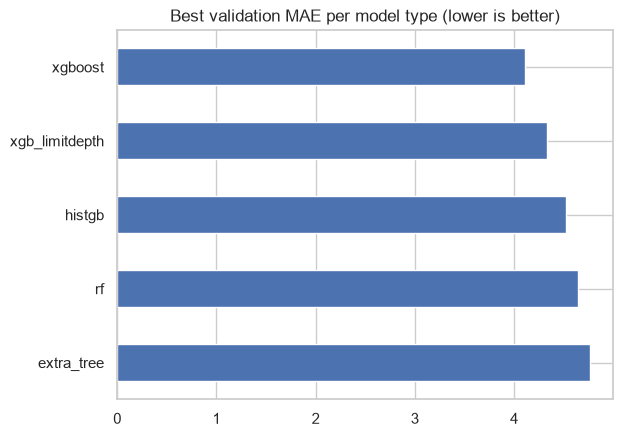

In [4]:
board = (pd.Series(automl.best_loss_per_estimator, name="valid_MAE")
           .dropna().sort_values().to_frame())
board["family"] = ["boosting" if e in ("xgboost", "xgb_limitdepth", "histgb") else "bagging" for e in board.index]
board.to_csv("models/flaml_leaderboard.csv")
display(board.round(4))
board["valid_MAE"].plot(kind="barh", title="Best validation MAE per model type (lower is better)")
plt.gca().invert_yaxis(); plt.show()

## 3. Validation score, then refit and test score
1. **Validation:** predictions of the model trained on *train only*. This should match FLAML's own number; we check that.
2. **Refit** the same model with the same hyperparameters on *train + validation*, so it also learns from the most recent year.
3. **Test:** score the refitted model on the untouched test year, once.

*Note on `year`:* tree models cannot extrapolate. For the test year they behave as if it were the last year they saw. That is one more reason to refit on the validation year.

In [5]:
best_name = automl.best_estimator
final = automl.model                      # FLAML wrapper: best model type + tuned hyperparameters

pred_va = np.clip(final.predict(X_va), 0, None)           # model trained on train only
valid_metrics = regression_metrics(y_va, pred_va)
print("validation:", valid_metrics, "| FLAML said", round(automl.best_loss, 4))

final.fit(pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va]))   # same hyperparameters, more data
pred = np.clip(final.predict(X_te), 0, None)
test_metrics = regression_metrics(y_te, pred)
print("test      :", test_metrics)

tag = f"flaml_{best_name}" + (f"_from{TRAIN_FROM_YEAR}" if TRAIN_FROM_YEAR else "")
save_metrics(tag, valid_metrics, test_metrics, where="local",
             note=f"FLAML best of {ESTIMATORS}, {TIME_BUDGET}s budget; config {automl.best_config}")

import joblib
joblib.dump({"model": final.estimator, "features": FEATURES, "stations": STATIONS}, "models/flaml_best.pkl")
print(f"model file: {Path('models/flaml_best.pkl').stat().st_size / 1e6:.0f} MB")

validation: {'MAE': 4.092187881469727, 'RMSE': 6.527757504839789, 'R2': 0.6711406707763672} | FLAML said 4.1089
test      : {'MAE': 4.226107120513916, 'RMSE': 6.62656340955473, 'R2': 0.6887346506118774}
model file: 43 MB


## 4. Compare with the baselines from 04
Ranked on **validation** MAE.

In [6]:
load_metrics()[["valid_MAE", "valid_RMSE", "valid_R2", "test_MAE", "test_RMSE", "test_R2", "where"]].round(3)

,valid_MAE,valid_RMSE,valid_R2,test_MAE,test_RMSE,test_R2,where
flaml_xgboost,4.092188,6.527758,0.671141,4.226107,6.626563,0.688735,local
baseline_seasonal_naive,4.816103,7.624048,0.551406,5.205211,8.409907,0.498655,local
baseline_last_year,5.075872,7.867899,0.522251,5.447443,8.278868,0.514157,local
linear_ridge,5.937776,9.137574,0.355617,6.322705,9.51637,0.358057,local
global_mean,8.359283,11.477536,-0.016669,8.935258,11.878421,-0.000165,local


## 5. First error analysis
Where does the model go wrong? Error by hour of day, per month, by station, and one example week (test year).

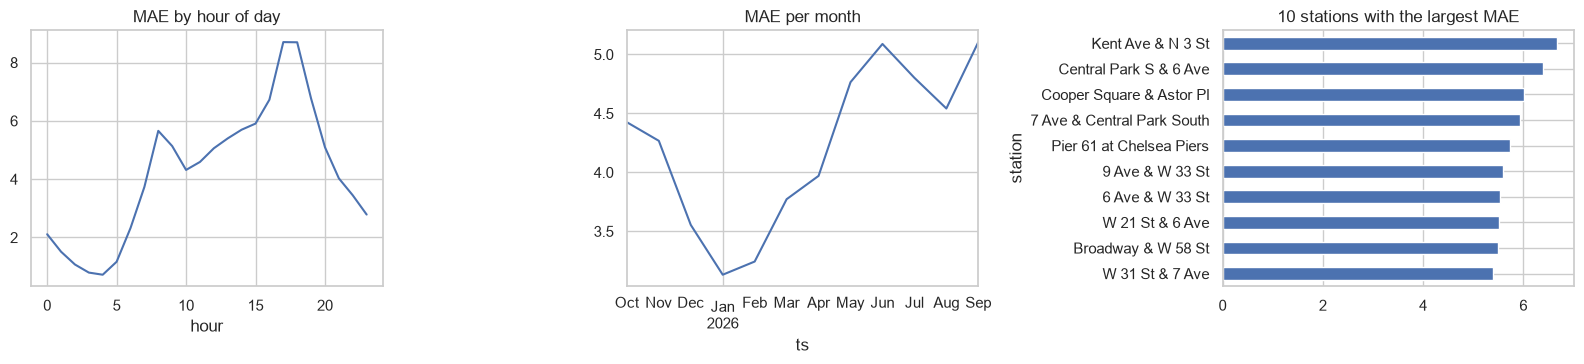

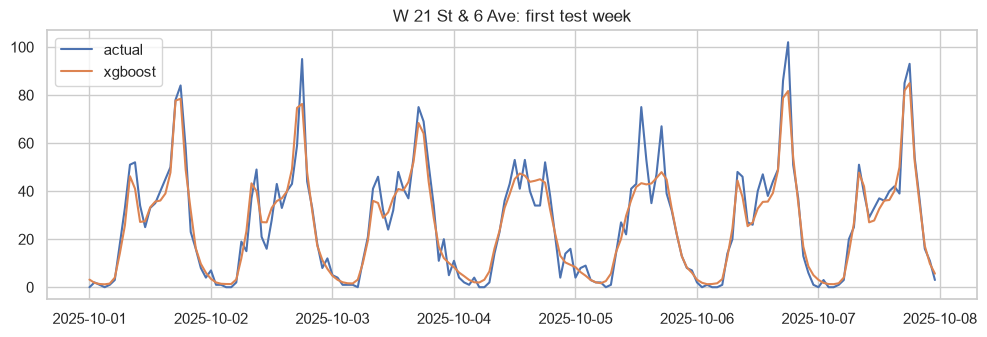

In [7]:
res = test_index.assign(actual=y_te.values, pred=pred)
res["abs_err"] = (res.actual - res.pred).abs()
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
res.groupby("hour")["abs_err"].mean().plot(ax=ax[0], title="MAE by hour of day")
res.set_index("ts")["abs_err"].resample("MS").mean().plot(ax=ax[1], title="MAE per month")
res.groupby("station", observed=True)["abs_err"].mean().sort_values().tail(10).plot(
    kind="barh", ax=ax[2], title="10 stations with the largest MAE")
plt.tight_layout(); plt.show()

st = res.groupby("station", observed=True)["actual"].sum().idxmax()
wk = res[res.station == st].iloc[: 24 * 7]
plt.figure(figsize=(12, 3.5))
plt.plot(wk.ts, wk.actual, label="actual"); plt.plot(wk.ts, wk.pred, label=best_name)
plt.title(f"{st}: first test week"); plt.legend(); plt.show()

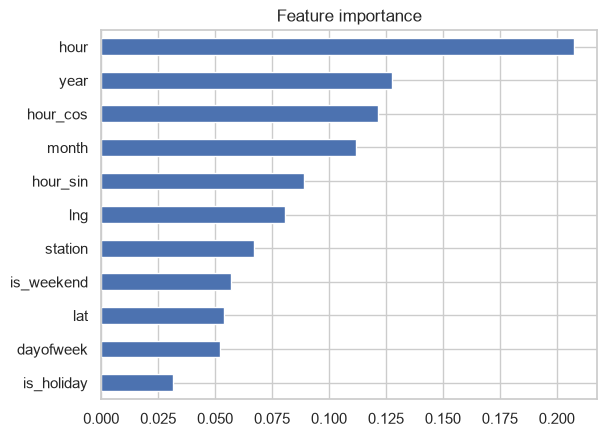

In [8]:
imp = pd.Series(final.estimator.feature_importances_, index=FEATURES).sort_values()
imp.plot(kind="barh", title="Feature importance"); plt.show()

## Conclusion

The FLAML experiment showed that **boosting performed substantially better than bagging** on the validation set. The best boosting model, XGBoost, achieved a validation MAE of **4.1089**, while the best bagging model, Random Forest, achieved **4.6426**. Therefore, boosting reduced the average error by approximately **0.534 trips per hour**, or **11.5%** relative to the best bagging model. This agrees with the theory: bagging mainly reduces variance by averaging many trees, while boosting reduces bias by building trees sequentially to correct previous errors. For this demand-prediction problem, reducing bias was more important than only reducing variance.

XGBoost was also clearly better than the strongest baseline from notebook 04, the seasonal-naive model. The seasonal-naive baseline had a validation MAE of **4.8161**, compared with **4.0922** for the FLAML XGBoost model. This represents an improvement of approximately **0.724 trips per hour**, or **15.0% lower MAE**. The result shows that the machine-learning model captures additional relationships between station, calendar, and time features that the simple seasonal baseline cannot capture.

The error analysis shows that the model's largest errors occur during high-demand hours, especially around commuting periods, because mistakes are naturally larger when the total number of trips is high. Errors also vary by month and station. Some stations have more unpredictable demand than others, likely because of their location, nearby offices, residential areas, or connections to transport hubs. The model also makes large errors on unusual days when demand differs substantially from the normal calendar pattern. Since the current feature set does not include weather or detailed event information, it cannot recognize the effect of heavy rain, snow, extreme temperatures, festivals, sporting events, or transit disruptions. The months in the test period cover a complete year, so the seasonal differences are more likely to reflect real demand patterns rather than an incomplete month.

The feature-importance results indicate that the model relies most on the variables describing **station identity and time**, particularly station, hour, day of week, and the seasonal/calendar features. The latitude and longitude variables also help distinguish location-specific demand patterns. Holiday and weekend indicators provide additional information, but they are less powerful on their own. These results are consistent with the problem: demand depends strongly on where the station is and when the trip occurs.

In this run, `TRAIN_FROM_YEAR` was set to `None`, so the model was trained using all available training years. A later-year-only experiment was not used for the reported result; therefore, it is not possible to conclude from this run whether removing older data would help or hurt. Such an experiment would be useful because recent years may better represent current travel behavior, but removing older data would also reduce the amount of training information. Overall, FLAML successfully identified XGBoost as the strongest model family, providing a significant improvement over the baselines, while weather and event data remain the most promising ways to reduce the remaining large errors.
